# Pixel Baselines 

We build multiple baselines and analyze their performance.

Classifiers analyzed:

- logistic regression using RGB pixels
- logistic regression using RGB pixels + pixel XY coordinate

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from semseg.config import load_experiment_config, load_dataset_config
from semseg.data.dataset import NYUDepthV2Dataset
from semseg.data import binarize_mask, load_splits
from semseg.evaluation.metrics import evaluate_binary_segmentation
from semseg.features.pixel import build_pixel_dataset, image_features
from semseg.paths import DATA_RAW_DIR, OUTPUTS_DIR
from semseg.utils import load_checkpoint, load_json
from semseg.visualization import (
    plot_classifier_performance,
    plot_segmentation_samples,
)

## Logistic Classifier: RGB Pixels

We build a Logistic Classifier on raw RGB pixels of each image in order to determine the class.

In [2]:
RUN_NAME = "pixel_logreg_rgb"
RUN_DIR = OUTPUTS_DIR / RUN_NAME
PLOT_N_SAMPLES = 5
SAVE_FIGS = True
if SAVE_FIGS:
    FIGS_PATH = RUN_DIR / "figures"
    FIGS_PATH.mkdir(exist_ok=True)

exp_cfg = load_experiment_config(RUN_DIR / "config.yaml")
ds_cfg = load_dataset_config(RUN_DIR / "dataset_config.yaml")

dataset = NYUDepthV2Dataset(DATA_RAW_DIR / ds_cfg.filename)
train_indices, validation_indices, test_indices = load_splits(
    RUN_DIR / "results" / "splits.json"
)
model = load_checkpoint(RUN_DIR / "checkpoints" / "model.joblib")
validation_metrics = load_json(RUN_DIR / "results" / "validation_metrics.json")
target_ids = [dataset.get_class_id(name) for name in exp_cfg.task.target_classes]

print(ds_cfg)
print(f"\nTraining images: {len(train_indices)}")
print(f"Validation images: {len(validation_indices)}")
print(f"Test images: {len(test_indices)}\n")
print(exp_cfg)

DatasetConfig(nyu_depth_v2):
  name            : 'nyu_depth_v2'
  filename        : 'nyu_depth_v2_labeled.mat'
  ignore_index    : 0
  split           : SplitConfig(random_state=42, val_fraction=0.15, test_fraction=0.15)

Training images: 1028
Validation images: 206
Test images: 215

ExperimentConfig(pixel_logreg_rgb):
  name            : 'pixel_logreg_rgb'
  dataset_config_path: 'datasets/nyu_depth_v2.yaml'
  random_state    : 42
  sampling        : SamplingConfig(strategy='pixel', stride=6, with_position=False)
  task            : TaskConfig(type='binary_segmentation', target_classes=['floor', 'floor mat', 'floor trim'], class_names=['not floor', 'floor'], threshold=0.5)
  model           : ModelConfig(name='logistic_regression', params={'class_weight': 'balanced', 'max_iter': 1000})
  output          : OutputConfig(save_checkpoint=True, save_predictions=True)


In [3]:
X_test, y_test = build_pixel_dataset(
    dataset,
    test_indices,
    target_ids,
    stride=exp_cfg.sampling.stride,
    with_position=exp_cfg.sampling.with_position,
    ignore_index=ds_cfg.ignore_index,
)
y_test_proba = model.predict_proba(X_test)
y_test_pred = model.predict(X_test, threshold=exp_cfg.task.threshold)
test_metrics = evaluate_binary_segmentation(y_test, y_test_pred, y_test_proba)

for split_name, metrics in (
    ("Validation (saved)", validation_metrics),
    ("Test", test_metrics),
):
    print(
        f"{split_name:20} "
        f"AUC: {metrics['auc']:.3f} | AP: {metrics['ap']:.3f} | "
        f"Accuracy: {metrics['accuracy']:.3f} | IoU: {metrics['iou']:.3f}"
    )

print("Test confusion matrix [not floor, floor]:")
print(test_metrics["confusion_matrix"])

Validation (saved)   AUC: 0.613 | AP: 0.166 | Accuracy: 0.566 | IoU: 0.140
Test                 AUC: 0.635 | AP: 0.167 | Accuracy: 0.572 | IoU: 0.150
Test confusion matrix [not floor, floor]:
[[767352 601895]
 [ 60029 116922]]


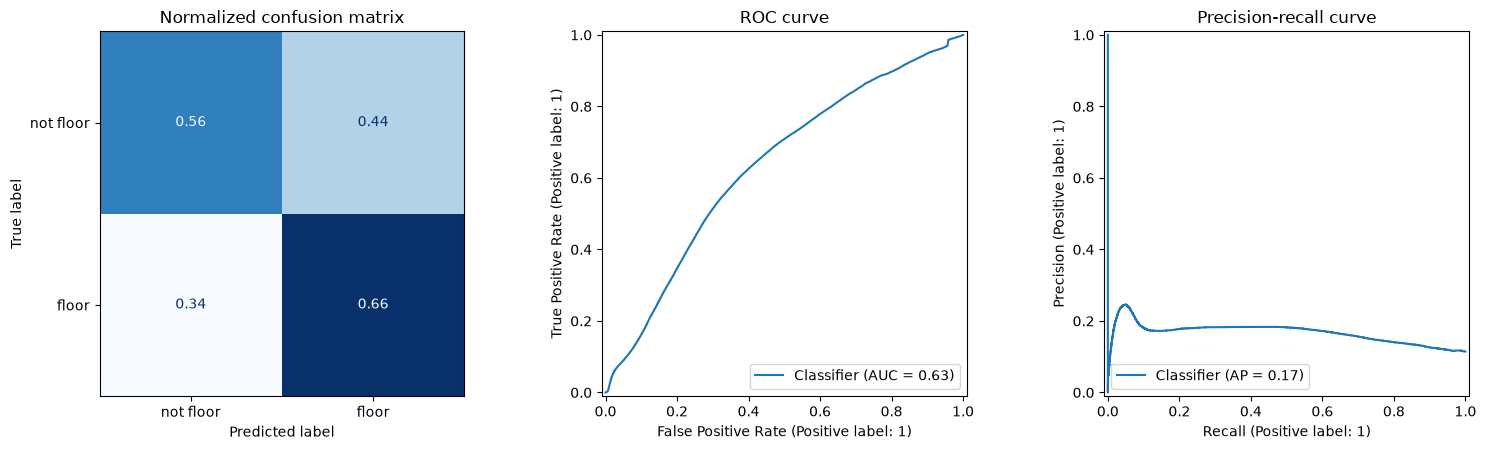

In [4]:
fig, axes = plot_classifier_performance(
    y_true=y_test,
    y_pred=y_test_pred,
    y_proba=y_test_proba,
    class_names=exp_cfg.task.class_names,
    save_path=FIGS_PATH / f"{RUN_NAME}_performance.png",
)
plt.show()

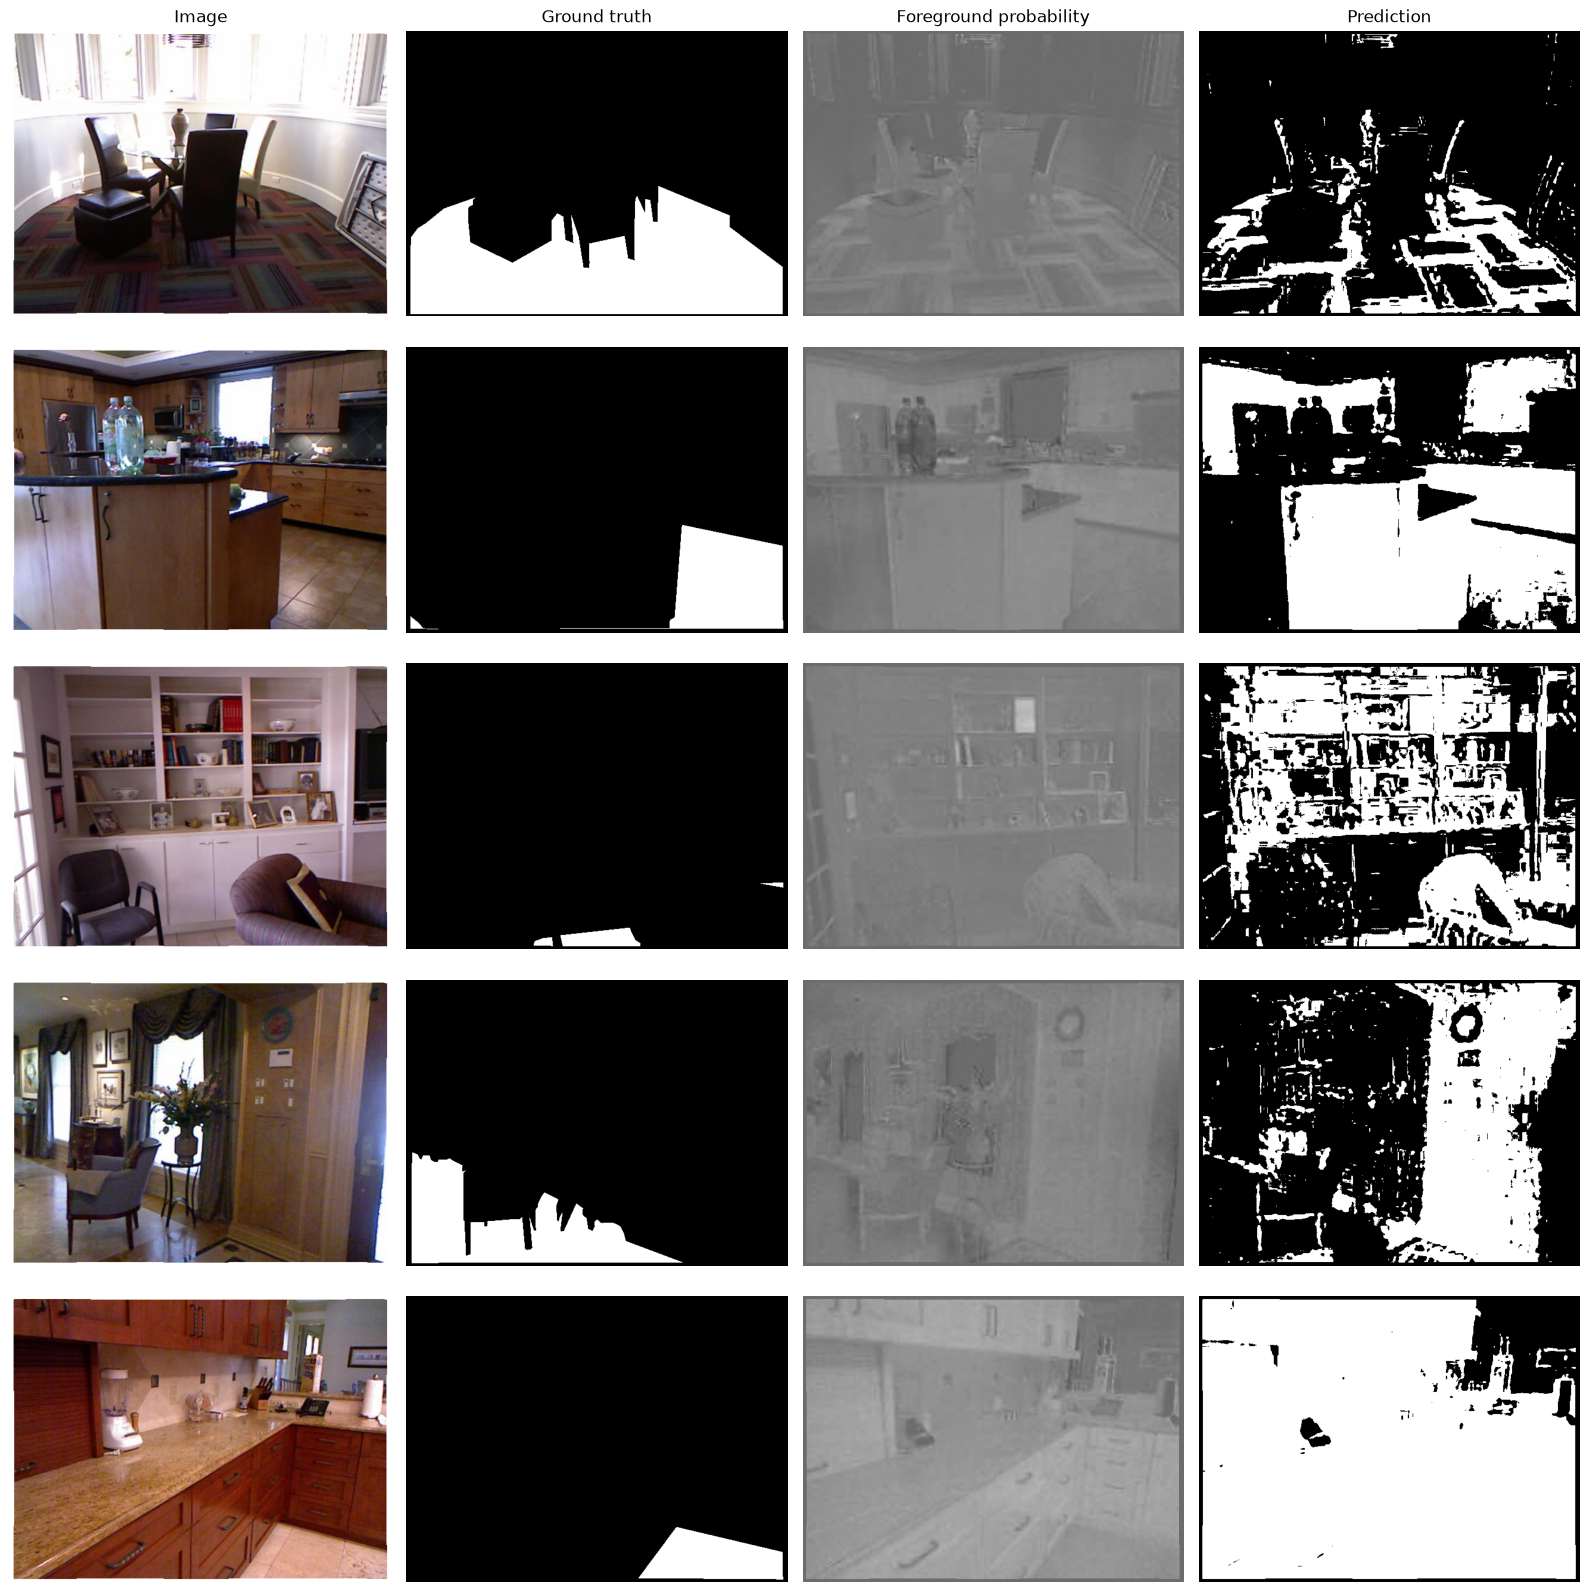

In [5]:
sample_indices = test_indices[:PLOT_N_SAMPLES]
images = []
ground_truth = []
predictions = []
probabilities = []

for index in sample_indices:
    image, labels = dataset.get_pair(index)
    features = image_features(image, with_position=exp_cfg.sampling.with_position)
    probability = model.predict_proba(features).reshape(labels.shape)
    prediction = (probability >= exp_cfg.task.threshold).astype(np.uint8)

    images.append(image)
    ground_truth.append(binarize_mask(labels, target_ids))
    predictions.append(prediction)
    probabilities.append(probability)

fig, axes = plot_segmentation_samples(
    images=images,
    ground_truth=ground_truth,
    predictions=predictions,
    probabilities=probabilities,
    indices=sample_indices,
    max_samples=PLOT_N_SAMPLES,
    save_path=FIGS_PATH / f"{RUN_NAME}_samples.png",
)
plt.show()

Baseline achieves poor, barely over random chance, performance which is to be expected given the complexity of the dataset and the task.

The visalization of the samples highlights how model classifies each pixel using solely its color and inferred intensity resulting in some samples (e.g. no.5) producing anomalously large number of pixels assigned as floor.

## Logistic Classifier: RGB Pixels + XY position

We develop on top of the baseline by introducing features representing XY position of each pixel.

In [6]:
RUN_NAME = "pixel_logreg_rgbxy"
RUN_DIR = OUTPUTS_DIR / RUN_NAME
PLOT_N_SAMPLES = 5
SAVE_FIGS = True
if SAVE_FIGS:
    FIGS_PATH = RUN_DIR / "figures"
    FIGS_PATH.mkdir(exist_ok=True)

exp_cfg = load_experiment_config(RUN_DIR / "config.yaml")
ds_cfg = load_dataset_config(RUN_DIR / "dataset_config.yaml")

dataset = NYUDepthV2Dataset(DATA_RAW_DIR / ds_cfg.filename)
train_indices, validation_indices, test_indices = load_splits(
    RUN_DIR / "results" / "splits.json"
)
model = load_checkpoint(RUN_DIR / "checkpoints" / "model.joblib")
validation_metrics = load_json(RUN_DIR / "results" / "validation_metrics.json")
target_ids = [dataset.get_class_id(name) for name in exp_cfg.task.target_classes]

print(ds_cfg)
print(f"\nTraining images: {len(train_indices)}")
print(f"Validation images: {len(validation_indices)}")
print(f"Test images: {len(test_indices)}\n")
print(exp_cfg)

DatasetConfig(nyu_depth_v2):
  name            : 'nyu_depth_v2'
  filename        : 'nyu_depth_v2_labeled.mat'
  ignore_index    : 0
  split           : SplitConfig(random_state=42, val_fraction=0.15, test_fraction=0.15)

Training images: 1028
Validation images: 206
Test images: 215

ExperimentConfig(pixel_logreg_rgbxy):
  name            : 'pixel_logreg_rgbxy'
  dataset_config_path: 'datasets/nyu_depth_v2.yaml'
  random_state    : 42
  sampling        : SamplingConfig(strategy='pixel', stride=6, with_position=True)
  task            : TaskConfig(type='binary_segmentation', target_classes=['floor', 'floor mat', 'floor trim'], class_names=['not floor', 'floor'], threshold=0.5)
  model           : ModelConfig(name='logistic_regression', params={'class_weight': 'balanced', 'max_iter': 1000})
  output          : OutputConfig(save_checkpoint=True, save_predictions=True)


In [7]:
X_test, y_test = build_pixel_dataset(
    dataset,
    test_indices,
    target_ids,
    stride=exp_cfg.sampling.stride,
    with_position=exp_cfg.sampling.with_position,
    ignore_index=ds_cfg.ignore_index,
)
y_test_proba = model.predict_proba(X_test)
y_test_pred = model.predict(X_test, threshold=exp_cfg.task.threshold)
test_metrics = evaluate_binary_segmentation(y_test, y_test_pred, y_test_proba)

for split_name, metrics in (
    ("Validation (saved)", validation_metrics),
    ("Test", test_metrics),
):
    print(
        f"{split_name:20} "
        f"AUC: {metrics['auc']:.3f} | AP: {metrics['ap']:.3f} | "
        f"Accuracy: {metrics['accuracy']:.3f} | IoU: {metrics['iou']:.3f}"
    )

print("Test confusion matrix [not floor, floor]:")
print(test_metrics["confusion_matrix"])

Validation (saved)   AUC: 0.880 | AP: 0.418 | Accuracy: 0.773 | IoU: 0.310
Test                 AUC: 0.889 | AP: 0.451 | Accuracy: 0.775 | IoU: 0.308
Test confusion matrix [not floor, floor]:
[[1044476  324771]
 [  22375  154576]]


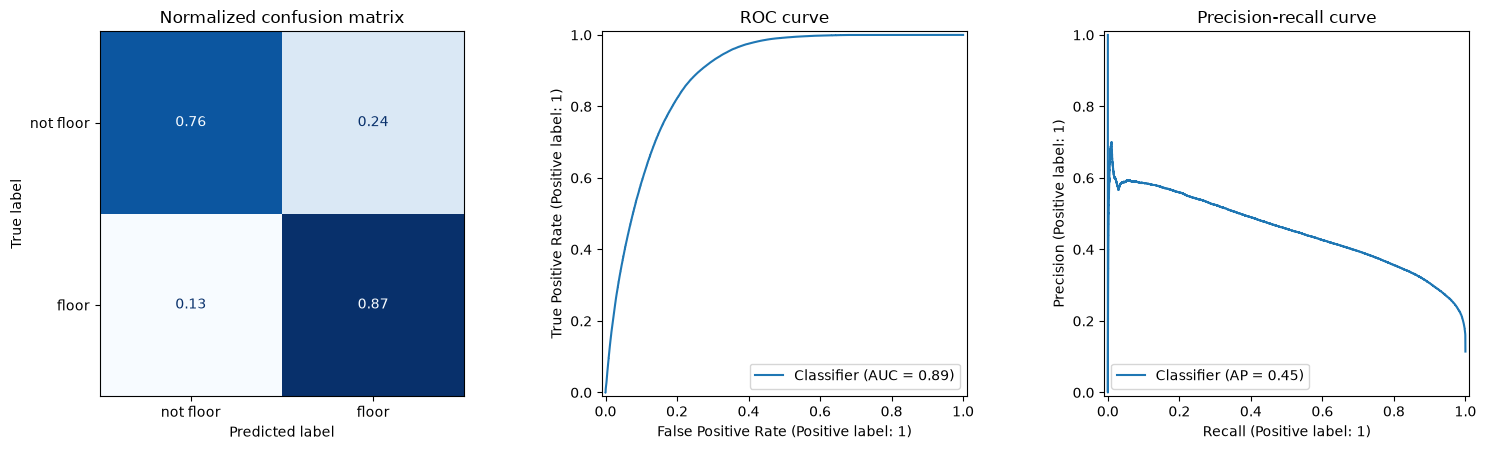

In [8]:
fig, axes = plot_classifier_performance(
    y_true=y_test,
    y_pred=y_test_pred,
    y_proba=y_test_proba,
    class_names=exp_cfg.task.class_names,
    save_path=FIGS_PATH / f"{RUN_NAME}_performance.png",
)
plt.show()

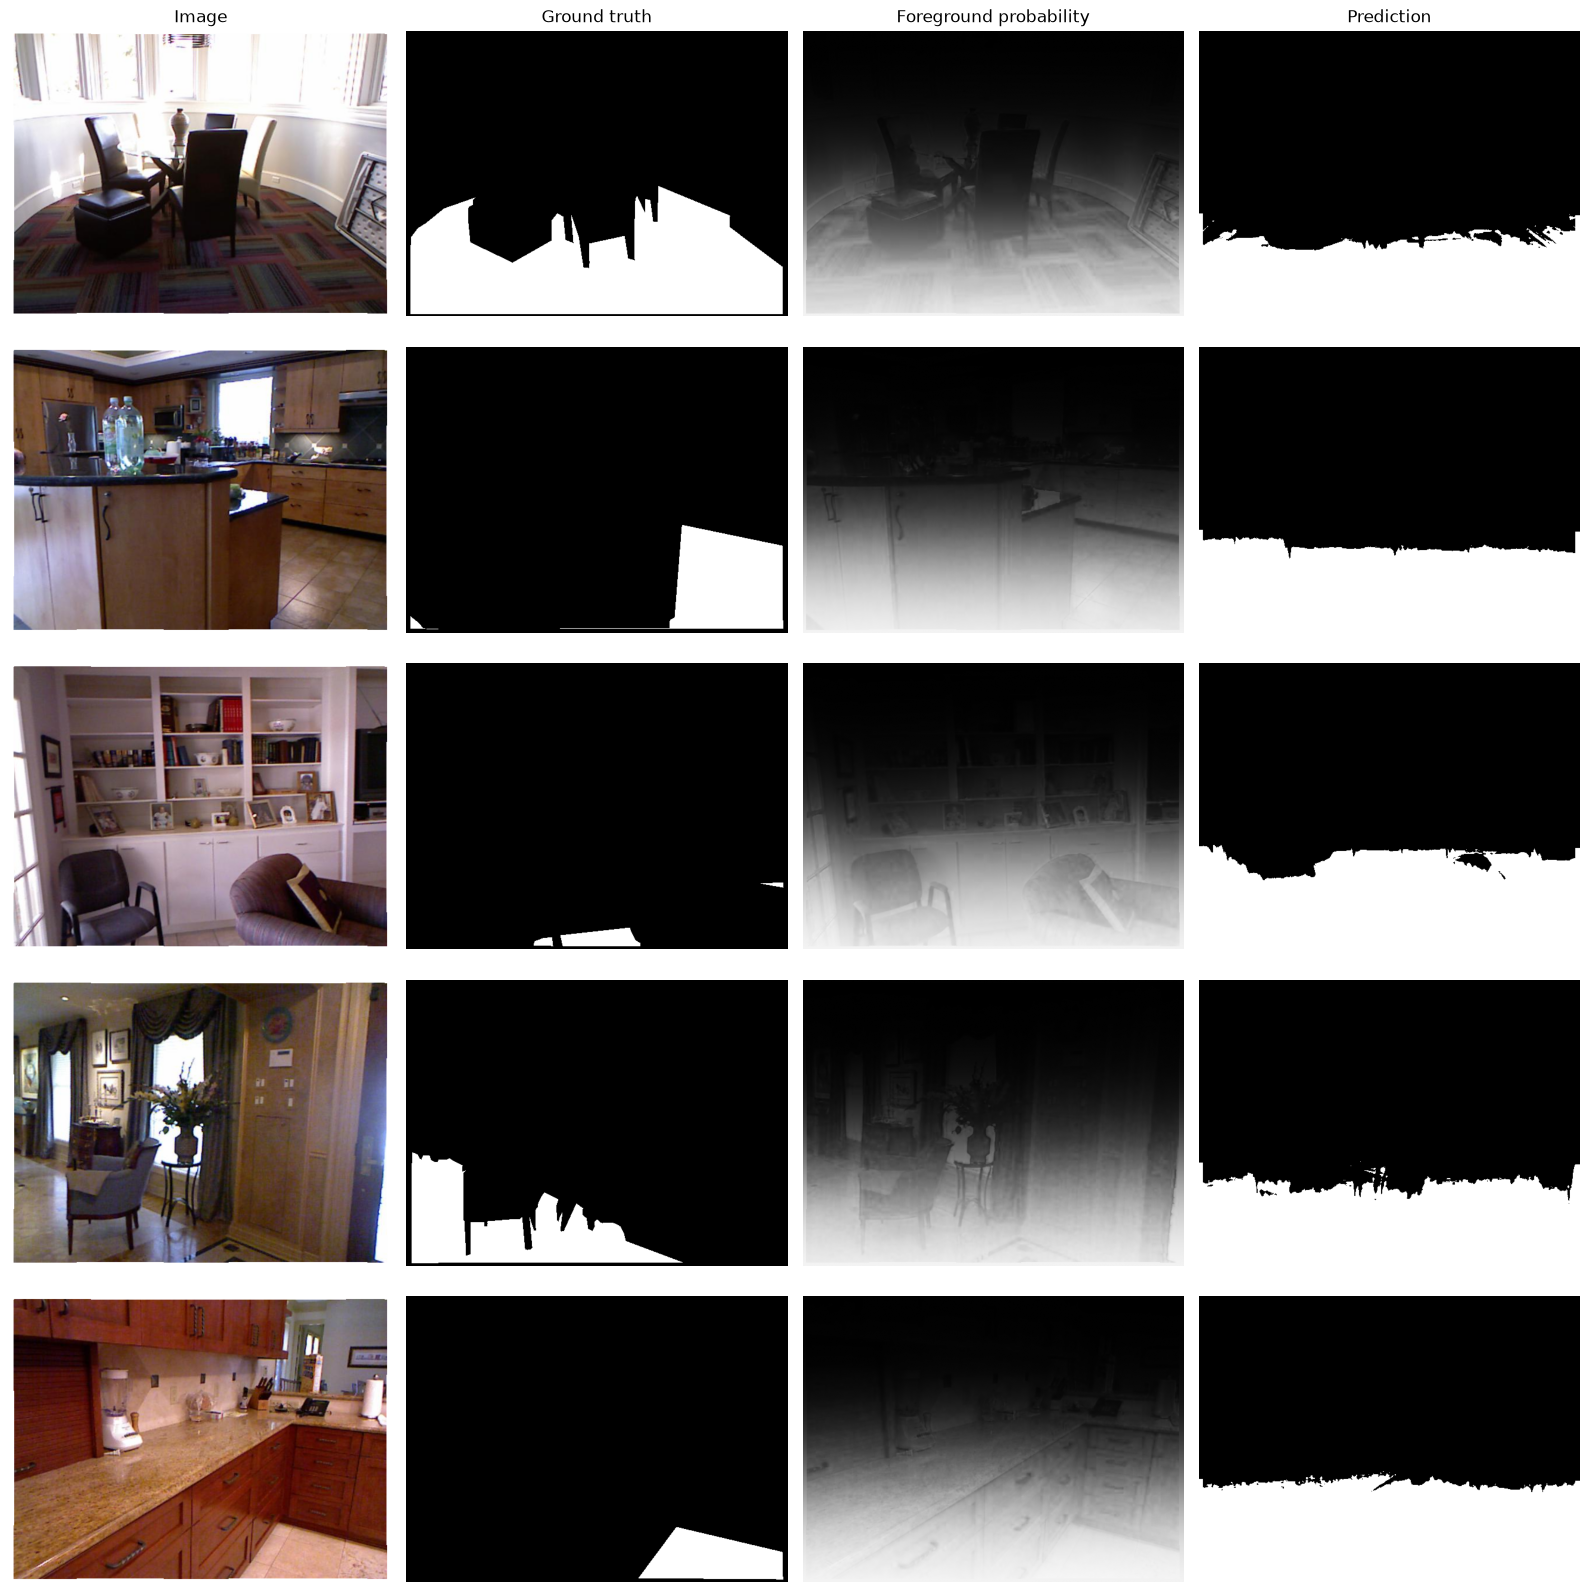

In [9]:
sample_indices = test_indices[:PLOT_N_SAMPLES]
images = []
ground_truth = []
predictions = []
probabilities = []

for index in sample_indices:
    image, labels = dataset.get_pair(index)
    features = image_features(image, with_position=exp_cfg.sampling.with_position)
    probability = model.predict_proba(features).reshape(labels.shape)
    prediction = (probability >= exp_cfg.task.threshold).astype(np.uint8)

    images.append(image)
    ground_truth.append(binarize_mask(labels, target_ids))
    predictions.append(prediction)
    probabilities.append(probability)

fig, axes = plot_segmentation_samples(
    images=images,
    ground_truth=ground_truth,
    predictions=predictions,
    probabilities=probabilities,
    indices=sample_indices,
    max_samples=PLOT_N_SAMPLES,
    save_path=FIGS_PATH / f"{RUN_NAME}_samples.png",
)
plt.show()

Providing each pixel coordinates enabled the model to distinguish in a basic manner the relative position of pixels. This allowed model to capture the fact that the floor classes are generally at the bottom of an image, which improved the performance of the classifier significantly.

It should be noted, however, that predictions produced are still in large part incorrect, requiring more advanced approaches.

## Close

In [10]:
dataset.close()